In [1]:
import glob
import numpy as np
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
from matplotlib.ticker import FormatStrFormatter
import matplotlib.ticker as mticker
import matplotlib.colors
from matplotlib import rcParams
from matplotlib import ticker

In [2]:
#Constants
mJy = 1.0e-26
dist = 1.72*3.0856e21  # Distance to the source = 2.4 kpc
h = 6.6260755e-27     # erg.seg
eV = 1.602176e-12     # 1 eV = 1.602176e-12 erg
a = 4.0*np.pi*dist**2    

In [3]:
def read_SED(filename):
    '''This function reads the frequency and fluxes of the spectrum'''
    
    fname = filename
    SED = np.loadtxt(fname) # E, L_unabs, L_abs
    #E = SED[:,0] 
    #L_abs = SED[:,2] * 1.05 # THIS IS ARBITRARY TO MAKE A BETTER LOOKING FIT!!!!
    
    #nu = E * eV/h * 1e-9
    
    nu = SED[:,0]*1e-9
    S = SED[:,1]
    #S = L_abs*h/a/mJy 
    
    return nu, S

In [4]:
# Armo los objetos con los puntos observacionales

#ATCA_data = np.loadtxt('../data_radio_apep.dat')
#nu_ATCA, nu_ATCA_err = ATCA_data[:,0], ATCA_data[:,2]
#flux_ATCA, flux_ATCA_err = ATCA_data[:,1], ATCA_data[:,3] 

# MSX (Benaglia+2010)
msx_data = np.loadtxt('Benaglia_2010.dat')
nu_msx, nu_msx_err = msx_data[:,0], 0.1*msx_data[:,0]
flux_msx, flux_msx_err = msx_data[:,1], msx_data[:,1]*0.1

# jVLA (Benaglia+2021)
jvla_data = np.loadtxt('Benaglia_2021.dat')
nu_jvla, nu_jvla_err = jvla_data[:,0], jvla_data[:,2]
flux_jvla, flux_jvla_err = 1000.*jvla_data[:,1],1000.*jvla_data[:,3]

# Feathered data (Moutzouri+2022)
feat_data = np.loadtxt('Moutzouri_2022.dat')
nu_feat, nu_feat_err = feat_data[:,0], feat_data[:,1]/2.
flux_feat, flux_feat_err = (feat_data[:,2]-feat_data[:,3]), 0.05*(feat_data[:,2]-feat_data[:,3])

# VdE 2022
nu_VdE = np.array([0.8875])
nu_VdE_err = np.array([0.288/2.])

HD_319881 = np.array([5.97])
HD_319881_err = 0.05*HD_319881

RCW_49_S1 = np.array([12.6])
RCW_49_S1_err = 0.05*RCW_49_S1

G1 = np.array([8.0])
G1_err = 0.05*G1

HIP_98418 = np.array([5.3])
HIP_98418_err = 0.05*HIP_98418

HIP_88652 = np.array([2.24])
HIP_88652_err = 0.05*HIP_88652

In [5]:
# Read the names of the files with the SEDs (sync and windff)
files_syn_SEDs = glob.glob('../S_syn_RS.dat') # sync RS
files_syn_SEDs.sort()

files_ff_SEDs = glob.glob('../S_ff_FS.dat') # post shock f-f
files_ff_SEDs.sort()

files_ion_ff_SEDs = glob.glob('../S_ionizedFS.dat') # cooled layer in FS ionized by the star f-f
files_ion_ff_SEDs.sort()

files_ion_ISM_SEDs = glob.glob('../flux_ISM.dat') # unshocked ISM ionized by the star

print(files_syn_SEDs)
print(files_ff_SEDs)
print(files_ion_ff_SEDs)

['../S_syn_RS.dat']
['../S_ff_FS.dat']
['../S_ionizedFS.dat']


In [6]:
# Read each SED and store it in a list of SEDs
SEDs_syn = []
for file_syn in files_syn_SEDs:
    SED_syn = read_SED(file_syn)
    SEDs_syn.append(SED_syn)

SEDs_ff = []
for file_ff in files_ff_SEDs:
    SED_ff = np.loadtxt(file_ff) # nu, S_nu in Hz, mJy
    SED_ff[:,0] = SED_ff[:,0] * 1e-9 # Hz --> GHz
    SEDs_ff.append(SED_ff)
    
SEDs_ion = []
for file_ion in files_ion_ff_SEDs:
    SED_ion = np.loadtxt(file_ion) # nu, S_nu in Hz, mJy
    SED_ion[:,0] = SED_ion[:,0] * 1e-9 # Hz --> GHz
    SEDs_ion.append(SED_ion)
    
SEDs_ISM = []
for file_ISM in files_ion_ISM_SEDs:
    SED_ISM = np.loadtxt(file_ISM)
    SED_ISM[:,0] = SED_ISM[:,0] * 1e-9
    SEDs_ISM.append(SED_ISM)
    
# Store the Mdot values in a list
#Mdots = []
#i = 0
#for file in files_syn_SEDs:
#    Mdots.append(int(file.split('.')[0].split('_M')[-1]))

In [7]:
# Defino la función a ajustar
def po(x, F0, alpha0):
    """Power law function"""
    return( F0*np.power(x,alpha0) )

In [8]:
# Ajusto una función a S_ff para luego evaluarla en nu_syn y poder sumar S_tot = S_syn + S_ff (para cada Mdot)

# Primero defino los valores semilla para el ajuste (mismos para todas )
seed = np.array([0.1, 0.6]) # F0[1GHz], alpha0

SEDs_tot = []
for i in range(len(SEDs_ff)):
    popt, pcov = curve_fit(po, xdata=SEDs_ff[i][:,0], ydata=(SEDs_ff[i][:,1]+SEDs_ion[i][:,1]), p0=seed)
    SED_ff2 = po(SEDs_syn[i][0], *popt)
    popt, pcov = curve_fit(po, xdata=SEDs_ISM[i][:,0], ydata=SEDs_ISM[i][:,1], p0=seed)
    SED_ff3 = po(SEDs_syn[i][0], *popt)
    SED_tot = SEDs_syn[i][1] + SED_ff2# + SED_ff3 # syn + ff
    
    SEDs_tot.append(SED_tot)

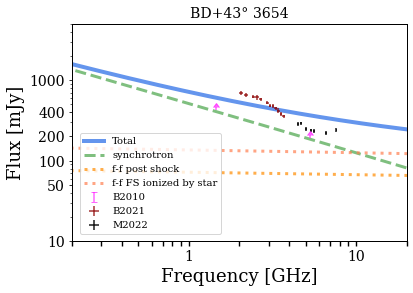

In [11]:
# Voy a graficar datos y modelo
fig, ax = plt.subplots(1)

# Defino una paleta discreta
n = 1#len(Mdots)
color_vector = np.linspace(0.2,0.9,n)
colors = plt.cm.copper_r(color_vector) # define a palette avoiding extreme colors
# Genero una colorbar discreta para n puntos
c = np.arange(1, n+1) 
cmap = plt.cm.get_cmap('copper_r', n)
norm = matplotlib.colors.BoundaryNorm(np.arange(n+1)+0.5,n)
#sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

# Definiciones estéticas
nice_fonts = {
        # Use LaTeX to write all text
#        "text.usetex": True,
        "font.family": 'serif',
        # Use 10pt font in plots, to match 10pt font in document
        "axes.labelsize": 18,
        "font.size": 14,
        "axes.linewidth":1,
        "axes.titlesize":14,
        # Make the legend/label fonts a little smaller
        "legend.fontsize": 14,
        "xtick.labelsize": 14,
        "ytick.labelsize": 14,
        "xtick.major.size": 5,     # major tick size in points
        "xtick.minor.size": 5,       # minor tick size in points
        "xtick.major.width": 1.4,     # major tick width in points
        "xtick.minor.width": 1.4,     # minor tick width in points
}
matplotlib.rcParams.update(nice_fonts)

# Set labels
#plt.setp(ax, xlabel=r"$\nu$ [GHz]")
plt.setp(ax, xlabel=r"Frequency [GHz]")
#plt.setp(ax, ylabel=r"$S_\nu$ [mJy]")
plt.setp(ax, ylabel=r"Flux [mJy]")

# Definiciones generales
plt.xlim(0.2, 20)
plt.ylim(300,5000.)
#plt.ylim(0.01,50)

# Grafico las funciones individuales y su suma usando una paleta discreta
for i in range(n):
    plt.plot(SEDs_syn[i][0], SEDs_tot[i], ls='-', color='cornflowerblue', linewidth=4, label='Total', zorder=1)
    plt.plot(SEDs_syn[i][0], SEDs_syn[i][1], ls='--', color='green', linewidth=3, alpha=0.5, label='synchrotron', zorder=1)
    plt.plot(SEDs_ff[i][:,0], SEDs_ff[i][:,1], ls=':', color='darkorange', linewidth=3, alpha=0.7, label='f-f post shock', zorder=1)
    plt.plot(SEDs_ion[i][:,0], SEDs_ion[i][:,1], ls=':', color='coral', linewidth=3, alpha=0.7, label='f-f FS ionized by star', zorder=1)

# Grafico cada set de datos y sus barras de error
# BD+43°3654
plt.title('BD+43° 3654')
plt.errorbar(nu_msx, flux_msx, yerr=flux_msx_err, lolims=True, ecolor='magenta', alpha=0.6, fmt='none', label='B2010',zorder=2)#, , ecolor='blue', alpha=0.8, fmt='none', label = 'Benaglia+2010')
plt.errorbar(nu_jvla, flux_jvla, yerr=flux_jvla_err, xerr=nu_jvla_err, ecolor='darkred', alpha=0.8, fmt='none', label = 'B2021',zorder=2)
plt.errorbar(nu_feat, flux_feat, yerr=flux_feat_err, xerr=nu_feat_err, ecolor='k', alpha=0.9, fmt='none', label = 'M2022', zorder=2)

# HD 319881
#plt.title('HD 319881')
#plt.errorbar(nu_VdE, HD_319881, yerr=HD_319881_err, xerr=nu_VdE_err, ecolor='darkred', alpha=0.8, fmt='none', label = 'vdE2022',zorder=2)

# RCW 49 S1
#plt.title('RCW 49 S1')
#plt.errorbar(nu_VdE, RCW_49_S1, yerr=RCW_49_S1_err, xerr=nu_VdE_err, ecolor='darkred', alpha=0.8, fmt='none', label = 'vdE2022',zorder=2)

# G1
#plt.title('G1')
#plt.errorbar(nu_VdE, G1, yerr=G1_err, xerr=nu_VdE_err, ecolor='darkred', alpha=0.8, fmt='none', label = 'vdE2022',zorder=2)

# HIP 98418
#plt.title('HIP 98418')
#plt.errorbar(nu_VdE, HIP_98418, yerr=HIP_98418_err, xerr=nu_VdE_err, ecolor='darkred', alpha=0.8, fmt='none', label = 'vdE2022',zorder=2)

# HIP 88652
#plt.title('HIP 88652')
#plt.errorbar(nu_VdE, HIP_88652, yerr=HIP_88652_err, xerr=nu_VdE_err, ecolor='darkred', alpha=0.8, fmt='none', label = 'vdE2022',zorder=2)

#plt.legend( bbox_to_anchor=(-0.18, 1.02, 1., .102), loc='lower left', ncol=3,prop={'size': 10},fontsize=22)
plt.legend( bbox_to_anchor=(0.01, 0.01, 1., .102), loc='lower left', ncol=1,prop={'size': 10},fontsize=22)
ax.loglog()
#ax.xaxis.set_minor_formatter(mticker.ScalarFormatter())
#ax.yaxis.set_major_formatter(ticker.ScalarFormatter())
ax.set_yscale('log')
ax.set_yticks([10,50,100,200,400,1000])
#ax.set_yticks([0.1,1,10])
ax.set_xticks([1,10])
ax.get_yaxis().set_major_formatter(matplotlib.ticker.ScalarFormatter())
ax.get_xaxis().set_major_formatter(matplotlib.ticker.ScalarFormatter())
#cbar = fig.colorbar(sm, ticks=c, label=r"$\dot{M}$ [$10^{-5}$ M$_\odot$ yr$^{-1}$]", pad=0.02)
#cbar.ax.set_yticklabels(Mdots)  # vertically oriented colorbar

#ax.text(7., 40., r'$\alpha = 2.4$',family='serif', fontsize=11)
#ax.text(3., 6., r'$\eta_{\rm B} = 0.9$',family='serif', fontsize=11)
#ax.text(7., 6., r'$L_{\rm inj,e} = 0.25 L_\perp$',family='serif', fontsize=11)
#ax.text(6.5, 0.03, r'$\eta_{\rm B} = 0.1$',family='serif', fontsize=11)
#ax.text(6.5, 0.015, r'$L_{\rm inj,e} = 0.01 L_\perp$',family='serif', fontsize=11)
#ax.text(0.22, 750., "BD+43° 3654", family='serif', fontsize=11)
#ax.text(3., 50., r'$\eta_{\rm B} = 0.1 \quad L_{\rm inj,e} = 0.01 L_\perp$',family='serif', fontsize=11)
#ax.text(0.108, 50., "HD 319881", family='serif', fontsize=11)

plt.show()

In [10]:
#fig.savefig('BD+43_test.png', bbox_inches='tight', pad_inches = 0)